In [ ]:
import torch
from transformers import BertTokenizer, BertForSequenceClassification
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import json
import warnings
warnings.filterwarnings('ignore')
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.optim import AdamW
from datasets import load_dataset
from google.colab import files
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import json
import warnings
warnings.filterwarnings('ignore')

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# HuggingFace
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)
from sentence_transformers import SentenceTransformer


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


Using device: cuda
GPU: NVIDIA A100-SXM4-40GB


Combined dataset length:  11543
Combined dataset length after removing duplicates:  6808
Class distribution (0 = Legitimate, 1 = Malicious)
 label
0    5399
1    1409
Name: count, dtype: int64
Average word length:  16.243537015276146
Max word length: 171


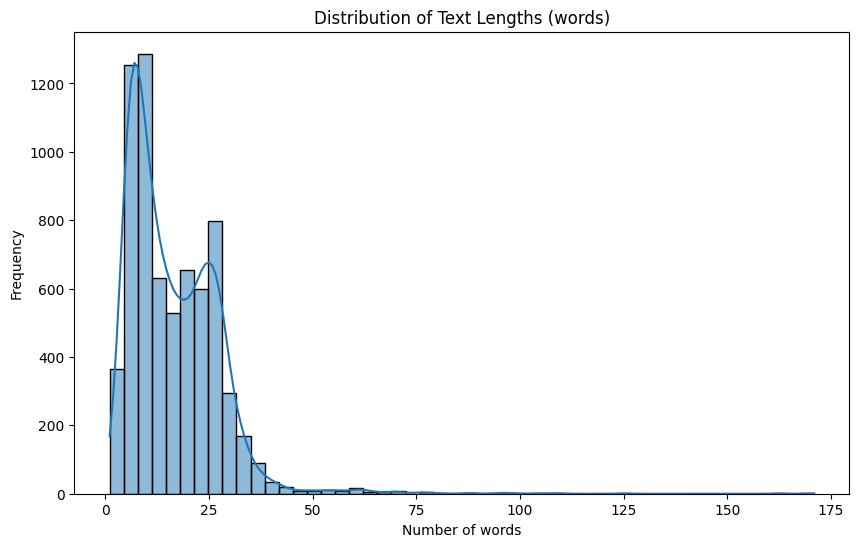

In [ ]:
data_mendeley = pd.read_csv("mendeley_dataset.csv",encoding='ISO-8859-1')
data_uci = pd.read_csv("uci_dataset.csv",encoding='ISO-8859-1')

data_mendeley_label=data_mendeley['LABEL']
data_mendeley_text=data_mendeley['TEXT']

data_uci_label=data_uci['v1']
data_uci_text=data_uci['v2']

data_mendeley = pd.concat(
    [data_mendeley_label.rename("label"),
     data_mendeley_text.rename("text")],
    axis=1
)

data_uci = pd.concat(
    [data_uci_label.rename("label"),
     data_uci_text.rename("text")],
    axis=1
)

data= pd.concat([data_mendeley, data_uci], ignore_index=True)
print("Combined dataset length: ",  len(data))

data = data.drop_duplicates(subset=["text"], keep="first")
print("Combined dataset length after removing duplicates: ", len(data))

label_map = {'ham':0, 'spam':1, 'Spam':1, 'smishing':1, 'Smishing':1}
data["label"] = data["label"].map(label_map)

class_counts = data["label"].value_counts()
print("Class distribution (0 = Legitimate, 1 = Malicious)\n",class_counts)

avg_word_length = data['text'].apply(lambda x: len(x.split())).mean()
print("Average word length: ", avg_word_length)

max_word_length = data['text'].apply(lambda x: len(x.split())).max()
print("Max word length:", max_word_length)

data['word_count'] = data['text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10,6))
sns.histplot(data['word_count'], bins=50, kde=True)
plt.title("Distribution of Text Lengths (words)")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()


In [ ]:
text_train,text_temp,labels_train,label_temp = train_test_split(
    data['text'],
    data['label'],
    test_size=0.3,
    random_state=SEED,
    stratify=data['label'])

text_val,text_test,labels_val,labels_test = train_test_split(
    text_temp,
    label_temp,
    test_size = 0.5,
    random_state=SEED,
    stratify=label_temp)

text_train = text_train.tolist()
text_val   = text_val.tolist()
text_test  = text_test.tolist()

labels_train_tensor = torch.tensor(labels_train.tolist())
labels_val_tensor   = torch.tensor(labels_val.tolist())
labels_test_tensor  = torch.tensor(labels_test.tolist())


In [ ]:
from torch.utils.data import TensorDataset
from datasets import Dataset
from torch.utils.data import DataLoader
tokenizer = BertTokenizer.from_pretrained("bert-base-cased")

text_train_tokenized = tokenizer(
    text_train,
    padding='max_length',
    truncation=True,
    max_length=128,
    return_tensors='pt'
)

text_val_tokenized = tokenizer(
    text_val,
    padding='max_length',
    truncation=True,
    max_length=128,
    return_tensors='pt'
)

text_test_tokenized = tokenizer(
    text_test,
    padding='max_length',
    truncation=True,
    max_length=128,
    return_tensors='pt'
)


train_dataset = Dataset.from_dict({
    "input_ids": text_train_tokenized["input_ids"],
    "attention_mask": text_train_tokenized["attention_mask"],
    "labels": labels_train_tensor
})

val_dataset = Dataset.from_dict({
    "input_ids": text_val_tokenized["input_ids"],
    "attention_mask": text_val_tokenized["attention_mask"],
    "labels": labels_val_tensor
})

test_dataset = Dataset.from_dict({
    "input_ids": text_test_tokenized["input_ids"],
    "attention_mask": text_test_tokenized["attention_mask"],
    "labels": labels_test_tensor
})

train_dataset.set_format("torch")
val_dataset.set_format("torch")
test_dataset.set_format("torch")



tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained("bert-base-cased", num_labels=2)

total_params = sum(p.numel() for p in model.parameters())
trainable_params= sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total Model Parameters: ", total_params)
print("Trainable Model Parameters: ", trainable_params)
print("Model Configuration \n:",model.config)

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total Model Parameters:  108311810
Trainable Model Parameters:  108311810
Model Configuration 
: BertConfig {
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "dtype": "float32",
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.57.2",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 28996
}



In [ ]:

training_args = TrainingArguments(
    output_dir='./results_security-BERT',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    weight_decay=0.01,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    greater_is_better=True,
    logging_dir='./logs',
    logging_steps=50,
    warmup_steps=100,
    save_total_limit=2,
    report_to='wandb',
    run_name='security_BERT'
)

print(" Training arguments configured")

 Training arguments configured


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    """Compute metrics for evaluation"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='binary'
    )

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [ ]:
import wandb
wandb.init(
    project="security_BERT",
    name="security_BERT",
    config={
        'model': 'security_BERT',
        'task': 'disinformation-detection',
        'learning_rate': training_args.learning_rate,
        'batch_size': training_args.per_device_train_batch_size,
        'epochs': training_args.num_train_epochs
    }
)

trainer = Trainer(
    model=BertForSequenceClassification.from_pretrained("bert-base-cased", num_labels=2),
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=BertTokenizer.from_pretrained("bert-base-cased"),
    compute_metrics=compute_metrics,
)


# Train the model
print("\nStarting RoBERTa fine-tuning...")
print("This may take 10-20 minutes depending on your GPU...")
train_result = trainer.train()

print("\nTraining complete!")

eval/accuracy,▁█▅▅
eval/f1,▁█▅▅
eval/loss,█▂▃▁
eval/precision,█▅▁▁
eval/recall,▁█▇▇
eval/runtime,█▆▃▁
eval/samples_per_second,▁▃▆█
eval/steps_per_second,▁▃▆█
train/epoch,▁▂▂▂▃▄▄▄▅▅▆▆▇▇██
train/global_step,▁▂▂▂▃▄▄▄▅▅▆▆▇▇██
+3,...


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Starting RoBERTa fine-tuning...
This may take 10-20 minutes depending on your GPU...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.108000,0.085736,0.980411,0.989744,0.914692,0.950739
2,0.021500,0.025339,0.996082,0.990521,0.990521,0.990521
3,0.024400,0.031160,0.992165,0.990338,0.971564,0.980861
4,0.003500,0.019240,0.995103,0.990476,0.985782,0.988124
5,0.000200,0.019748,0.995103,1.000000,0.976303,0.988010
6,0.000100,0.020916,0.995103,1.000000,0.976303,0.988010
7,0.000100,0.021790,0.994123,0.995169,0.976303,0.985646
8,0.000100,0.022778,0.995103,1.000000,0.976303,0.988010
9,0.000100,0.023268,0.995103,1.000000,0.976303,0.988010
10,0.000100,0.023509,0.995103,1.000000,0.976303,0.988010



Training complete!


In [ ]:
# ---- Evaluate on Test Set ----
print("\nEvaluating on the test dataset...")

test_results = trainer.evaluate(test_dataset)

print("\n===== Test Set Performance =====")
for key, value in test_results.items():
    print(f"{key}: {value:.4f}")



Evaluating on the test dataset...



===== Test Set Performance =====
eval_loss: 0.0399
eval_accuracy: 0.9912
eval_precision: 0.9856
eval_recall: 0.9717
eval_f1: 0.9786
eval_runtime: 0.5581
eval_samples_per_second: 1831.2330
eval_steps_per_second: 57.3380
epoch: 5.0000
